In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,LSTM,Input

In [3]:
df=pd.read_csv("AirPassengers.csv")

In [4]:
df

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121
...,...,...
139,1960-08,606
140,1960-09,508
141,1960-10,461
142,1960-11,390


In [5]:
df.columns=df.columns.str.replace("#","")

In [8]:
data=df["Passengers"].values.reshape(-1,1)
data

array([[112],
       [118],
       [132],
       [129],
       [121],
       [135],
       [148],
       [148],
       [136],
       [119],
       [104],
       [118],
       [115],
       [126],
       [141],
       [135],
       [125],
       [149],
       [170],
       [170],
       [158],
       [133],
       [114],
       [140],
       [145],
       [150],
       [178],
       [163],
       [172],
       [178],
       [199],
       [199],
       [184],
       [162],
       [146],
       [166],
       [171],
       [180],
       [193],
       [181],
       [183],
       [218],
       [230],
       [242],
       [209],
       [191],
       [172],
       [194],
       [196],
       [196],
       [236],
       [235],
       [229],
       [243],
       [264],
       [272],
       [237],
       [211],
       [180],
       [201],
       [204],
       [188],
       [235],
       [227],
       [234],
       [264],
       [302],
       [293],
       [259],
       [229],
       [203],
      

In [9]:
Scaler=StandardScaler()
data=Scaler.fit_transform(data)

In [10]:
data

array([[-1.40777884],
       [-1.35759023],
       [-1.24048348],
       [-1.26557778],
       [-1.33249593],
       [-1.21538918],
       [-1.10664719],
       [-1.10664719],
       [-1.20702441],
       [-1.34922546],
       [-1.47469699],
       [-1.35759023],
       [-1.38268454],
       [-1.29067209],
       [-1.16520057],
       [-1.21538918],
       [-1.29903686],
       [-1.09828242],
       [-0.9226223 ],
       [-0.9226223 ],
       [-1.02299951],
       [-1.23211871],
       [-1.3910493 ],
       [-1.17356534],
       [-1.1317415 ],
       [-1.08991766],
       [-0.85570415],
       [-0.98117567],
       [-0.90589276],
       [-0.85570415],
       [-0.68004402],
       [-0.68004402],
       [-0.80551554],
       [-0.98954044],
       [-1.12337673],
       [-0.95608137],
       [-0.91425753],
       [-0.83897462],
       [-0.73023263],
       [-0.83060985],
       [-0.81388031],
       [-0.52111343],
       [-0.42073621],
       [-0.320359  ],
       [-0.59639634],
       [-0

In [31]:
spit=int(len(data)*0.9)
train=data[:spit]
test=data[spit-12:]

In [32]:
def sequence(data):
    X,y=[],[]
    for i in range(len(data)-12):
        X.append(data[i:i+12])
        y.append(data[i+12])
    return np.array(X),np.array(y)

In [33]:
X_train,y_train=sequence(train)
X_test,y_test=sequence(test)

In [34]:
X_train.shape

(117, 12, 1)

In [35]:
X_test.shape

(15, 12, 1)

In [36]:
y_train.shape

(117, 1)

In [37]:
model=Sequential([
    Input(shape=(12,1)),
    LSTM(128),
    Dense(1)
])

In [38]:
model.compile(
    optimizer='adam',
    loss="mse"
)

In [39]:
model.fit(X_train,y_train,epochs=20,batch_size=32)

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.4329
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.2076
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.1843
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.1534
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.1513
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.1563
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.1493
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.1417
Epoch 9/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.1342
Epoch 10/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.1324
Epoch 11/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.1288 
Epoch 12/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.1238
Epoch 13/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.1199
Epoch 14/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.1175
Epoch 15/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.1134
Epoch 16/20
4/4 ━━━━━━━━━━━━━━━━━

In [40]:
pred=model.predict(X_test)
actual=Scaler.inverse_transform(y_test)
pred=Scaler.inverse_transform(pred)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 260ms/step


In [41]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
print("mse:",mean_squared_error(actual,pred))
print("mae:",mean_absolute_error(actual,pred))
      

mse: 2432.265227450989
mae: 33.981309000651045


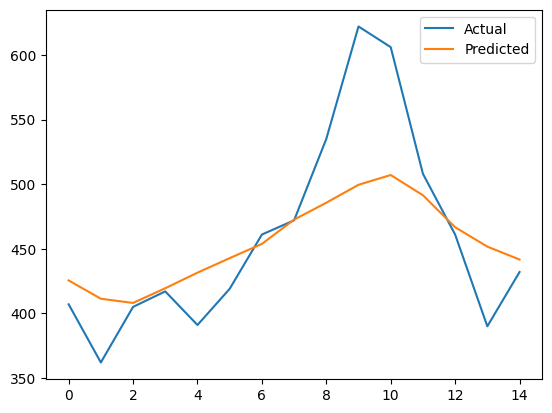

In [42]:
import matplotlib.pyplot as plt
plt.plot(actual, label="Actual")
plt.plot(pred, label="Predicted")
plt.legend()
plt.show()